# Visualize Representative Numerical Inputs and Token Graphs

This Visualize notebook generates demo trajectories and final-layer Llama-3.2-3B token graphs for the overview figure in the main text, using the cache produced by `Generate-token-graphs-across-dynamical-complexity.ipynb`.

The numerical inputs and token-graph visualizations follow the setup used in the main experiments.


Set imports, paths, and figure styles.


In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection

# Relative cache and figure paths
PROCESSED_DATA_DIR = Path('processed_graph_data')
FIGURE_OUTPUT_DIR = Path('figure')
TRAJECTORY_SAVE_FILENAME = 'overview-demo-trajectories.pdf'
GRAPH_SAVE_FILENAME = 'overview-demo-token-graphs.pdf'

# Retained inputs and analysis window
DATA_ORDER = ('Logistic r=3.2', 'Logistic r=3.5698', 'Logistic r=3.9')
REFERENCE_CONTEXT_TOKENS = 1000
ANALYSIS_CONTEXT_TOKENS = 500
CONTEXT_FRAC = ANALYSIS_CONTEXT_TOKENS / REFERENCE_CONTEXT_TOKENS
STATE_WINDOW_LENGTH = 500
STATE_TOKEN_POSITION_OFFSET = 1
STATE_TOKEN_POSITION_STEP = 2
FIGURE_DPI = 300

# Trajectory figure styles
TRAJECTORY_BACKGROUND_COLOR = '#F3F8FF'
TRAJECTORY_PANEL_TITLE_FONT_SIZE = 13.42
TRAJECTORY_AXIS_LABEL_FONT_SIZE = 13
TRAJECTORY_TICK_LABEL_FONT_SIZE = 13
TRAJECTORY_SAVEFIG_PAD_INCHES = 0.03
TRAJECTORY_RC_PARAMS = {
    'figure.facecolor': TRAJECTORY_BACKGROUND_COLOR,
    'axes.facecolor': TRAJECTORY_BACKGROUND_COLOR,
    'figure.dpi': FIGURE_DPI,
    'savefig.dpi': FIGURE_DPI,
    'savefig.facecolor': 'auto',
    'font.size': plt.rcParamsDefault['font.size'],
}

# Attention-graph style
RGB_GRAPH_EDGE_BASE_GRAY = 0.15
RGB_GRAPH_EDGE_ALPHA_MIN = 0.06
RGB_GRAPH_EDGE_ALPHA_SPAN = 0.52
RGB_GRAPH_EDGE_ALPHA_GAMMA = 0.85
RGB_GRAPH_EDGE_LW_MIN = 0.35
RGB_GRAPH_EDGE_LW_SPAN = 1.95
RGB_GRAPH_EDGE_LW_GAMMA = 0.90
RGB_GRAPH_NODE_SIZE = 18
RGB_GRAPH_DELIMITER_SIZE = 24
RGB_GRAPH_NODE_SIZE_FLOOR = 8
RGB_GRAPH_DELIMITER_SIZE_FLOOR = 10
RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE = False
RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR = 2.5
RGB_GRAPH_MAX_EDGES_DRAW = None
RGB_GRAPH_EDGE_STYLE_BINS = 20
LABEL_TOKEN_MARKERS = False
TOKEN_MARKER_LABELS_ONE_BASED = np.array([1, 100, 200, 300, 400, ANALYSIS_CONTEXT_TOKENS], dtype=int)
RGB_GRAPH_X_MARGIN = 0.04
RGB_GRAPH_Y_MARGIN = 0.10
# Token-graph figure layout and typography
GRAPH_BACKGROUND_COLOR = '#F6F3FA'
GRAPH_FIGURE_SIZE = (3.6, 9.2)
GRAPH_SUBPLOT_ADJUST = dict(left=0.005, right=0.995, bottom=0.000, top=0.960, wspace=0.0, hspace=0.095)
GRAPH_SAVEFIG_PAD_INCHES = 0.0
FONT_SIZE_SCALE = 1.10
PANEL_TITLE_FONT_SIZE = 14.6
PANEL_TITLE_Y_OFFSET = 0.001
GRAPH_RC_PARAMS = {
    'figure.facecolor': GRAPH_BACKGROUND_COLOR,
    'axes.facecolor': GRAPH_BACKGROUND_COLOR,
    'figure.dpi': FIGURE_DPI,
    'savefig.dpi': FIGURE_DPI,
    'savefig.facecolor': GRAPH_BACKGROUND_COLOR,
    'font.size': plt.rcParamsDefault['font.size'] * FONT_SIZE_SCALE,
}


Reconstruct the numerical inputs.


In [2]:
def logistic_sequence(r, x0, n):
    x = np.empty(n, dtype=float)
    x[0] = x0
    for i in range(1, n):
        x[i] = r * x[i - 1] * (1 - x[i - 1])
    return x


def settle_time_float(x, p, tol=1e-10):
    x = np.asarray(x, dtype=float)
    if p is None or p <= 0 or p >= x.size:
        return None
    err = np.abs(x[p:] - x[:-p])
    suffix_max = np.maximum.accumulate(err[::-1])[::-1]
    hits = np.flatnonzero(suffix_max < tol)
    return int(hits[0]) if hits.size else None


def build_burned_in_logistic_window(r, x0, n_window, expected_period=None, n_long=20000, tol=1e-10):
    if expected_period is None:
        return logistic_sequence(r, x0, n_window), 0

    x_long = logistic_sequence(r, x0, n_long)
    t_settle = settle_time_float(x_long, expected_period, tol=tol)
    if t_settle is None:
        raise ValueError(f'Could not find settle time for r={r} with expected period {expected_period}.')
    if t_settle + n_window > x_long.size:
        raise ValueError(f'Need a longer trajectory for r={r}; settle index {t_settle} leaves fewer than {n_window} states.')
    return np.asarray(x_long[t_settle:t_settle + n_window], dtype=float), int(t_settle)


def quantize_logistic_window(vals):
    vals = np.asarray(vals, dtype=float)
    vmin, vmax = float(vals.min()), float(vals.max())
    if vmax == vmin:
        return np.full(vals.shape[0], 500, dtype=int)
    return np.round(50 + (vals - vmin) / (vmax - vmin) * 900).astype(int)


logistic_period2_sequence, _ = build_burned_in_logistic_window(
    3.2, x0=0.2, n_window=STATE_WINDOW_LENGTH, expected_period=2,
)
logistic_period64_sequence, _ = build_burned_in_logistic_window(
    3.5698, x0=0.2, n_window=STATE_WINDOW_LENGTH, expected_period=64,
)
logistic_chaotic39_sequence = logistic_sequence(3.9, 0.2, STATE_WINDOW_LENGTH)


Plot and save the numerical-input demonstration.


In [3]:
def first_state_token_text(values, n_states=6):
    state_tokens = quantize_logistic_window(values)[:int(n_states)]
    return ','.join(f'{token:03d}' for token in state_tokens) + ',...'


def plot_logistic_state_trajectories(save=True, show=True):
    with plt.rc_context(TRAJECTORY_RC_PARAMS):
        trajectory_specs = [
            ('Logistic map r=3.2 (period 2)', logistic_period2_sequence, '#6DA9DC'),
            ('Logistic map r=3.5698 (period 64)', logistic_period64_sequence, '#2D5F9A'),
            ('Logistic map r=3.9 (chaotic)', logistic_chaotic39_sequence, '#B95D5D'),
        ]

        fig, axes = plt.subplots(
            len(trajectory_specs),
            1,
            figsize=(4.35, 6.50),
            dpi=FIGURE_DPI,
            sharex=True,
            gridspec_kw={'hspace': 1.65},
        )
        axes = np.ravel(np.asarray(axes))
        figure_background_color = '#F3F8FF'
        fig.patch.set_facecolor(figure_background_color)

        for ax, (title, values, line_color) in zip(axes, trajectory_specs):
            ax.set_facecolor(figure_background_color)
            values = np.asarray(values, dtype=float)
            token_positions = STATE_TOKEN_POSITION_OFFSET + STATE_TOKEN_POSITION_STEP * np.arange(values.size, dtype=float)
            first_100 = token_positions <= 100
            x = token_positions[first_100]
            y = values[first_100]
            y_min = float(np.min(y))
            y_max = float(np.max(y))
            y_pad = 0.12 * (y_max - y_min if y_max != y_min else 1.0)
            y_lower = y_min - y_pad
            y_upper = y_max + y_pad
            y_middle = 0.5 * (y_lower + y_upper)

            ax.plot(
                x,
                y,
                color=line_color,
                linewidth=1.25,
                alpha=0.95,
                marker='o',
                markersize=3.8,
                markerfacecolor=line_color,
                markeredgecolor=line_color,
                markeredgewidth=0.7,
                zorder=2,
            )
            ax.text(
                106,
                y_middle,
                '...',
                ha='left',
                va='center',
                fontsize=TRAJECTORY_PANEL_TITLE_FONT_SIZE + 4.0,
                color='black',
                clip_on=False,
            )
            ax.text(0.0, 1.52, title, transform=ax.transAxes, ha='left', va='bottom', fontsize=TRAJECTORY_PANEL_TITLE_FONT_SIZE, color='black')
            ax.text(
                0.0,
                1.18,
                first_state_token_text(values, n_states=6),
                transform=ax.transAxes,
                ha='left',
                va='bottom',
                fontsize=10.2,
                family='monospace',
                color='black',
            )
            ax.set_xlim(0, 112)
            ax.set_xticks([1, 50, 100])
            ax.set_xticklabels(['1', '50', '100'])
            ax.set_ylim(y_lower, y_upper)
            ax.set_yticks([])
            ax.set_xlabel('')
            ax.set_ylabel('')
            ax.grid(False)
            ax.tick_params(axis='x', labelbottom=True, bottom=True, labelsize=TRAJECTORY_TICK_LABEL_FONT_SIZE, length=3.0, width=0.8, pad=3.0, labelcolor='black', color='black')
            ax.tick_params(axis='y', labelsize=TRAJECTORY_TICK_LABEL_FONT_SIZE, length=0, pad=3.0)
            for spine in ('top', 'right', 'left'):
                ax.spines[spine].set_visible(False)
            ax.spines['bottom'].set_visible(True)
            ax.spines['bottom'].set_color('#666666')
            ax.spines['bottom'].set_linewidth(0.8)

        fig.supxlabel('Context length ($N$ tokens)', x=0.508, fontsize=TRAJECTORY_AXIS_LABEL_FONT_SIZE, y=0.030, color='black')
        fig.subplots_adjust(top=0.840, bottom=0.110, left=0.135, right=0.980)

        if save:
            FIGURE_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
            save_path = FIGURE_OUTPUT_DIR / TRAJECTORY_SAVE_FILENAME
            fig.savefig(save_path, bbox_inches='tight', pad_inches=TRAJECTORY_SAVEFIG_PAD_INCHES, dpi=FIGURE_DPI)
            print(f'Saved: {save_path}')

        if show:
            plt.show()

        return fig


Saved: figure/overview-demo-trajectories.pdf


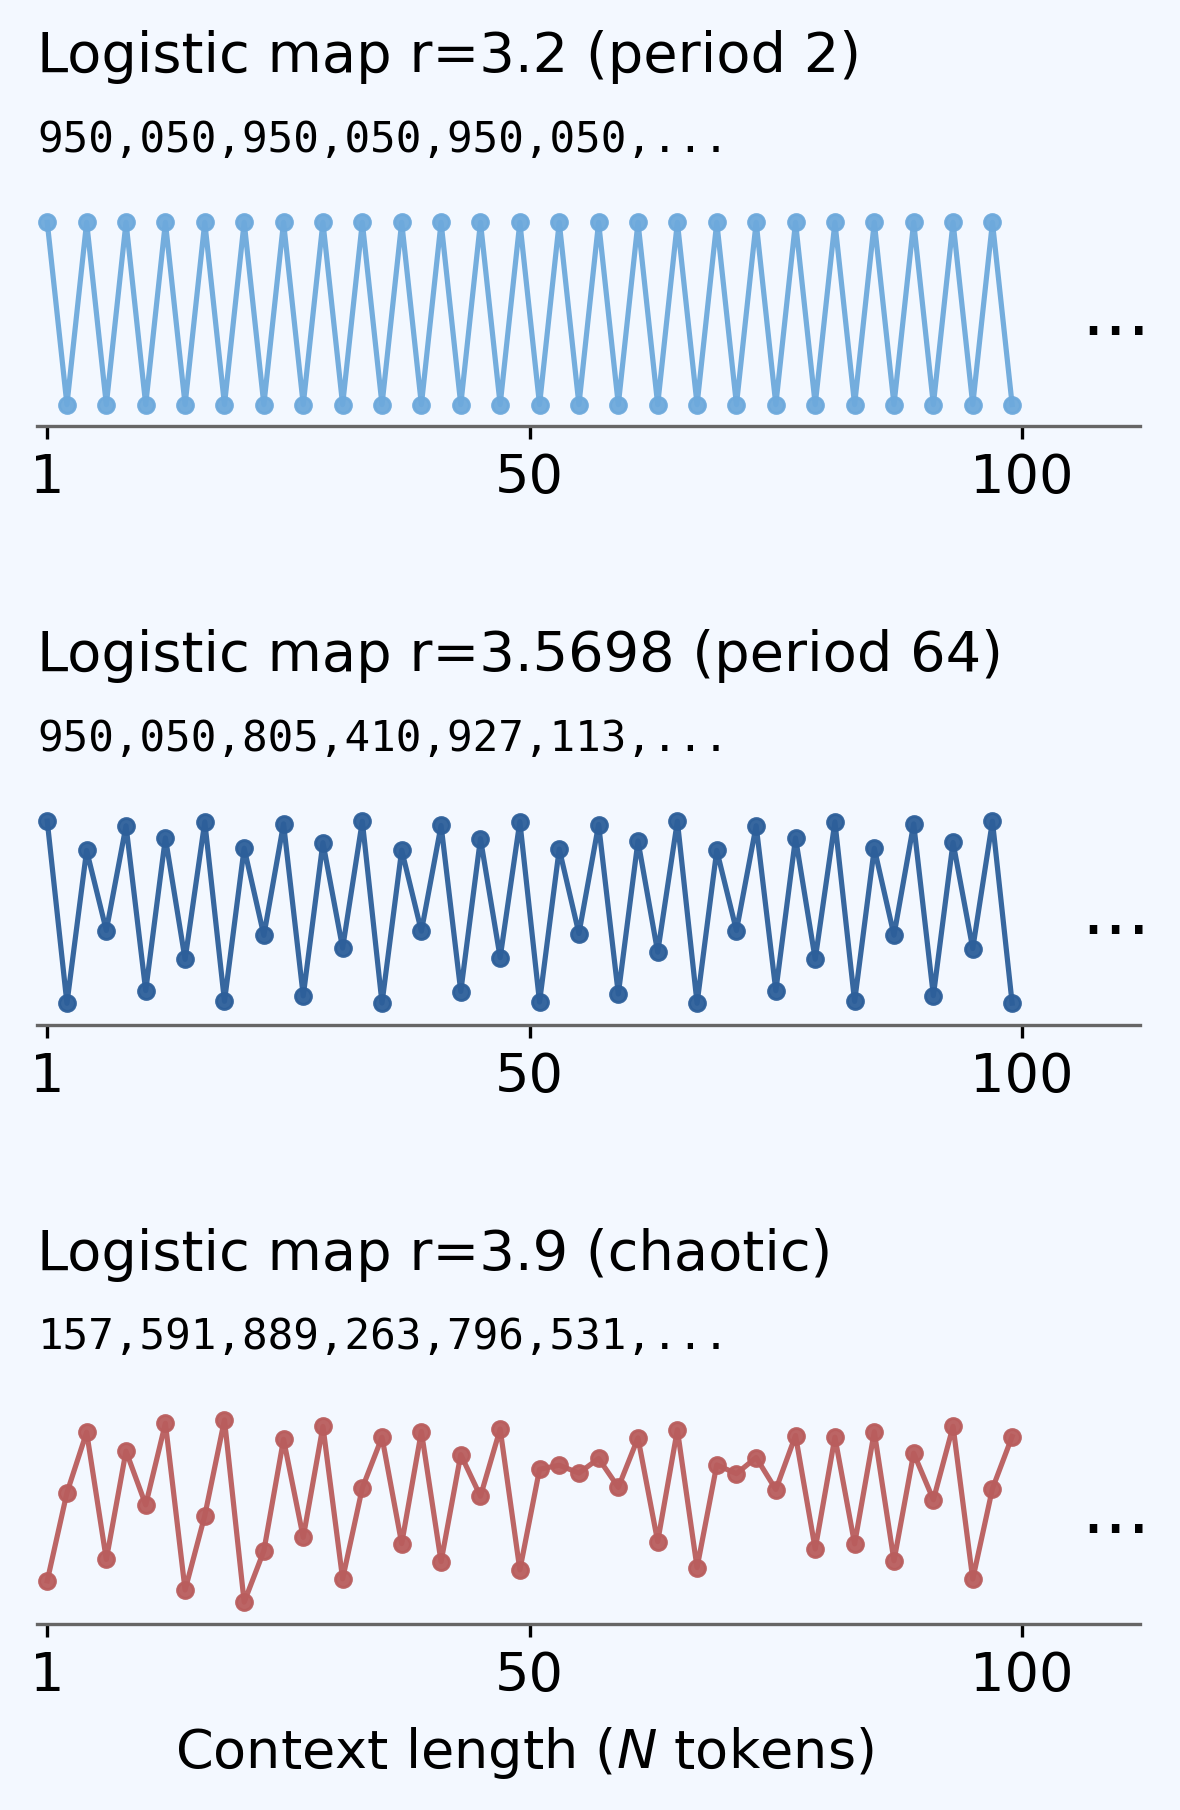

In [4]:
trajectory_figure = plot_logistic_state_trajectories(save=True, show=True);


Load the graph archives and plot the token-graph demonstration.


In [5]:
DATA_TITLE_OVERRIDES = {
    'Logistic r=3.2': 'Logistic period 2',
    'Logistic r=3.5698': 'Logistic period 64',
}
DATA_TITLE_SUFFIXES = {'Logistic r=3.9': 'chaotic'}

GRAPH_DATA_ARRAY_KEYS = (
    'layer_indices',
    'Wbar',
    'layout_positions',
    'svd_projection_coords',
    'svd_cumulative_energy_ratio',
    'is_delimiter',
)


def panel_title(data_name):
    data_name = str(data_name)
    title = DATA_TITLE_OVERRIDES.get(data_name, data_name)
    suffix = DATA_TITLE_SUFFIXES.get(data_name)
    return f'{title} ({suffix})' if suffix else title


def context_display_label(num_tokens=ANALYSIS_CONTEXT_TOKENS):
    return f'{int(num_tokens)} tokens'


def context_fraction_label(frac):
    pct = int(round(100 * float(frac)))
    return f'context{pct}'


def safe_data_stem(data_name, frac):
    name = str(data_name).replace('=', '_').replace('.', '_')
    name = re.sub(r'[^A-Za-z0-9]+', '_', name).strip('_').lower()
    return f'{name}_{context_fraction_label(frac)}'


def graph_data_path(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    return Path(data_dir) / f'{safe_data_stem(data_name, frac)}_graph_data.npz'


In [6]:
def load_processed_graph_data(data_name, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
    if not path.exists():
        raise FileNotFoundError(path)

    with np.load(path, allow_pickle=False) as npz:
        processed_data = {key: npz[key] for key in npz.files}

    missing = [key for key in GRAPH_DATA_ARRAY_KEYS if key not in processed_data]
    if missing:
        raise KeyError(f'{path} is missing required arrays: {missing}')
    extra = sorted(set(processed_data) - set(GRAPH_DATA_ARRAY_KEYS))
    if extra:
        raise KeyError(f'{path} contains unexpected arrays: {extra}')
    return processed_data


def check_processed_graph_data(data_names=DATA_ORDER, frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    missing = []
    invalid = []
    for data_name in data_names:
        path = graph_data_path(data_name, frac=frac, data_dir=data_dir)
        if not path.exists():
            missing.append(path)
            continue
        try:
            load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        except (OSError, KeyError, ValueError) as exc:
            invalid.append((path, exc))

    if missing:
        raise FileNotFoundError('Missing processed graph data:\n' + '\n'.join(str(path) for path in missing))
    if invalid:
        details = '\n'.join(f'{path}: {exc}' for path, exc in invalid)
        raise ValueError('Invalid processed graph data:\n' + details)


check_processed_graph_data(data_names=DATA_ORDER)
for data_name in DATA_ORDER:
    processed = load_processed_graph_data(data_name)
    layer_count = len(processed['layer_indices'])
    expected_shapes = {
        'Wbar': (layer_count, ANALYSIS_CONTEXT_TOKENS, ANALYSIS_CONTEXT_TOKENS),
        'layout_positions': (layer_count, ANALYSIS_CONTEXT_TOKENS, 2),
        'svd_projection_coords': (layer_count, ANALYSIS_CONTEXT_TOKENS, 3),
        'is_delimiter': (ANALYSIS_CONTEXT_TOKENS,),
    }
    for key, shape in expected_shapes.items():
        if processed[key].shape != shape or not np.all(np.isfinite(processed[key])):
            raise ValueError(f'{data_name}: invalid {key}; expected finite array of shape {shape}.')
print(f'Validated {len(DATA_ORDER)} existing {ANALYSIS_CONTEXT_TOKENS}-token graph archives.')


Validated 3 existing 500-token graph archives.


In [7]:
def edge_weight_threshold_from_uniform(n_nodes, factor):
    n_nodes = int(n_nodes)
    if n_nodes <= 0:
        return float('inf')
    return float(factor) / float(n_nodes)



def _minmax_scale_rgb_channels(coords, fill_value=0.5, eps=1e-12):
    coords = np.asarray(coords, dtype=float)
    if coords.ndim == 1:
        coords = coords[:, None]
    if coords.ndim != 2:
        raise ValueError('coords must be 2D (num_tokens x num_components)')

    n = coords.shape[0]
    rgb = np.full((n, 3), float(fill_value), dtype=float)
    if n == 0:
        return rgb

    for k in range(3):
        if coords.shape[1] <= k:
            continue
        col = np.asarray(coords[:, k], dtype=float)
        finite = np.isfinite(col)
        if not np.any(finite):
            continue
        cmin = float(np.min(col[finite]))
        cmax = float(np.max(col[finite]))
        if (cmax - cmin) <= float(eps):
            rgb[finite, k] = float(fill_value)
        else:
            rgb[finite, k] = (col[finite] - cmin) / (cmax - cmin)

    rgb[~np.isfinite(rgb)] = float(fill_value)
    return np.clip(rgb, 0.0, 1.0)


def select_top_edges(W, max_edges=None, threshold=None, threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR):
    W = np.asarray(W, dtype=float).copy()
    if W.ndim != 2 or W.shape[0] != W.shape[1]:
        raise ValueError('W must be square')

    n = W.shape[0]
    if n < 2:
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    W[~np.isfinite(W)] = 0.0
    np.fill_diagonal(W, 0.0)
    iu = np.triu_indices(n, k=1)
    w = W[iu]

    edge_threshold = edge_weight_threshold_from_uniform(n, threshold_factor) if threshold is None else float(threshold)
    pos_mask = np.isfinite(w) & (w > edge_threshold)
    if not np.any(pos_mask):
        return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)

    pos_idx = np.nonzero(pos_mask)[0]
    w_pos = w[pos_mask]

    if max_edges is None:
        chosen = pos_idx
    else:
        k = min(int(max_edges), w_pos.size)
        if k <= 0:
            return np.empty((0,), dtype=int), np.empty((0,), dtype=int), np.empty((0,), dtype=float)
        if k < w_pos.size:
            top_local = np.argpartition(w_pos, -k)[-k:]
            chosen = pos_idx[top_local]
        else:
            chosen = pos_idx

    order = np.argsort(w[chosen])[::-1]
    chosen = chosen[order]
    return iu[0][chosen], iu[1][chosen], w[chosen]


def token_marker_indices_and_labels(n, marker_labels_one_based=TOKEN_MARKER_LABELS_ONE_BASED):
    marker_labels = np.asarray(marker_labels_one_based, dtype=int)
    valid = (marker_labels >= 1) & (marker_labels <= int(n))
    marker_labels = marker_labels[valid]
    marker_indices = marker_labels - 1
    return marker_indices.astype(int), marker_labels.astype(int)


def annotate_token_position_markers(
    ax,
    x,
    y,
    marker_indices,
    marker_labels=None,
    label_markers=LABEL_TOKEN_MARKERS,
    label_position_overrides=None,
):
    marker_indices = np.asarray(marker_indices, dtype=int)
    if marker_labels is None:
        marker_labels = marker_indices + 1
    marker_labels = np.asarray(marker_labels, dtype=int)
    if marker_indices.size == 0:
        return

    valid = (marker_indices >= 0) & (marker_indices < len(x))
    marker_indices = marker_indices[valid]
    marker_labels = marker_labels[valid]
    if marker_indices.size == 0:
        return

    ax.scatter(
        x[marker_indices],
        y[marker_indices],
        s=70,
        facecolors='white',
        edgecolors='#111111',
        linewidths=1.35,
        alpha=0.98,
        zorder=7,
        clip_on=False,
    )

    if not label_markers:
        return

    label_position_overrides = label_position_overrides or {}
    for idx, label in zip(marker_indices, marker_labels):
        label_style = dict(xytext=(3, 3), ha='left', va='bottom')
        label_style.update(label_position_overrides.get(int(label), {}))
        ax.annotate(
            f'{int(label)}',
            (x[idx], y[idx]),
            xytext=label_style['xytext'],
            textcoords='offset points',
            fontsize=7.35 * FONT_SIZE_SCALE,
            fontweight='bold',
            ha=label_style['ha'],
            va=label_style['va'],
            color='#000000',
            bbox=dict(boxstyle='round,pad=0.14', facecolor='white', edgecolor='#111111', linewidth=0.35, alpha=0.92),
            zorder=8,
            annotation_clip=False,
            clip_on=False,
        )


def draw_processed_layer_on_ax(
    ax,
    W,
    xy,
    rgb,
    is_delimiter,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
    max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
    edge_weight_limits=None,
    label_token_markers=LABEL_TOKEN_MARKERS,
    marker_label_position_overrides=None,
):
    W = np.asarray(W, dtype=float)
    xy = np.asarray(xy, dtype=float)
    rgb = np.asarray(rgb, dtype=float)
    is_delimiter = np.asarray(is_delimiter, dtype=bool)

    n = min(W.shape[0], xy.shape[0], rgb.shape[0], is_delimiter.shape[0])
    if n == 0:
        ax.axis('off')
        return {'n': 0, 'edge_count': 0}

    W = W[:n, :n]
    xy = xy[:n]
    rgb = np.clip(rgb[:n], 0.0, 1.0)
    is_delimiter = is_delimiter[:n]
    x = xy[:, 0]
    y = xy[:, 1]

    i_idx, j_idx, w_edges = select_top_edges(
        W,
        max_edges=max_edges,
        threshold_factor=edge_threshold_factor,
    )

    if RGB_GRAPH_DRAW_TOKEN_ORDER_TRACE and n > 1:
        ax.plot(x, y, color='#BBBBBB', linewidth=0.6, alpha=0.5, zorder=1)

    if w_edges.size > 0:
        segments = np.stack([
            np.column_stack([x[i_idx], y[i_idx]]),
            np.column_stack([x[j_idx], y[j_idx]]),
        ], axis=1)

        if edge_weight_limits is None:
            w_min = float(np.min(w_edges))
            w_max = float(np.max(w_edges))
        else:
            w_min, w_max = (float(value) for value in edge_weight_limits)
        w_scaled = np.clip((w_edges - w_min) / (w_max - w_min), 0.0, 1.0) if w_max > w_min else np.ones_like(w_edges)
        n_style_bins = max(1, int(RGB_GRAPH_EDGE_STYLE_BINS))
        bin_indices = np.minimum((w_scaled * n_style_bins).astype(int), n_style_bins - 1)
        bin_centers = (np.arange(n_style_bins, dtype=float) + 0.5) / n_style_bins

        for bin_idx, bin_center in enumerate(bin_centers):
            mask = bin_indices == bin_idx
            if not np.any(mask):
                continue
            edge_alpha = RGB_GRAPH_EDGE_ALPHA_MIN + RGB_GRAPH_EDGE_ALPHA_SPAN * (bin_center ** RGB_GRAPH_EDGE_ALPHA_GAMMA)
            edge_lw = RGB_GRAPH_EDGE_LW_MIN + RGB_GRAPH_EDGE_LW_SPAN * (bin_center ** RGB_GRAPH_EDGE_LW_GAMMA)
            edge_rgba = (RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, RGB_GRAPH_EDGE_BASE_GRAY, edge_alpha)
            ax.add_collection(LineCollection(segments[mask], colors=[edge_rgba], linewidths=edge_lw, zorder=2))

    state_mask = ~is_delimiter
    if np.any(state_mask):
        ax.scatter(
            x[state_mask],
            y[state_mask],
            c=rgb[state_mask],
            s=max(float(RGB_GRAPH_NODE_SIZE_FLOOR), RGB_GRAPH_NODE_SIZE * 0.8),
            alpha=0.95,
            marker='o',
            edgecolors='none',
            zorder=3,
        )

    if np.any(is_delimiter):
        ax.scatter(
            x[is_delimiter],
            y[is_delimiter],
            c=rgb[is_delimiter],
            s=max(float(RGB_GRAPH_DELIMITER_SIZE_FLOOR), RGB_GRAPH_DELIMITER_SIZE * 0.8),
            alpha=0.95,
            marker='^',
            edgecolors='none',
            zorder=4,
        )

    if label_token_markers:
        marker_indices, marker_labels = token_marker_indices_and_labels(n)
        annotate_token_position_markers(
            ax,
            x,
            y,
            marker_indices,
            marker_labels=marker_labels,
            label_markers=label_token_markers,
            label_position_overrides=marker_label_position_overrides,
        )

    ax.set_aspect('equal', adjustable='box')
    ax.axis('off')
    ax.margins(x=RGB_GRAPH_X_MARGIN, y=RGB_GRAPH_Y_MARGIN)
    return {'n': int(n), 'edge_count': int(w_edges.size)}


In [8]:
def layer_offset(processed_data, layer_index):
    layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
    matches = np.nonzero(layer_indices == int(layer_index))[0]
    if matches.size == 0:
        available = ', '.join(str(int(layer)) for layer in layer_indices) if layer_indices.size else 'none'
        raise ValueError(f'Layer {layer_index} is unavailable. Available one-based layers: {available}')
    return int(matches[0])


def available_layer_indices(data_name=DATA_ORDER[0], frac=CONTEXT_FRAC, data_dir=PROCESSED_DATA_DIR):
    processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
    return np.asarray(processed_data['layer_indices'], dtype=int)


def add_row_aligned_panel_titles(fig, axes, titles, ncols=5):
    fig.canvas.draw()
    for row_start in range(0, len(titles), ncols):
        row_axes = axes[row_start:row_start + ncols]
        row_titles = titles[row_start:row_start + ncols]
        title_y = row_axes[0].get_position().y1 + PANEL_TITLE_Y_OFFSET
        for ax, title in zip(row_axes, row_titles):
            pos = ax.get_position()
            fig.text(
                pos.x0 + 0.5 * pos.width,
                title_y,
                title,
                ha='center',
                va='bottom',
                fontsize=PANEL_TITLE_FONT_SIZE,
            )


def collect_layer_panel_data_for_global_edge_norm(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    layer_index = int(layer_index)
    panel_data = []
    all_edge_weights = []

    for data_name in data_names:
        processed_data = load_processed_graph_data(data_name, frac=frac, data_dir=data_dir)
        layer_indices = np.asarray(processed_data['layer_indices'], dtype=int)
        offset = layer_offset(processed_data, layer_index)

        Wbar = np.asarray(processed_data['Wbar'], dtype=np.float32)[offset]
        layout_positions = np.asarray(processed_data['layout_positions'], dtype=np.float32)[offset]
        svd_projection_coords = np.asarray(processed_data['svd_projection_coords'], dtype=np.float32)[offset]
        rgb_colors = _minmax_scale_rgb_channels(svd_projection_coords).astype(np.float32)
        is_delimiter = np.asarray(processed_data['is_delimiter'], dtype=bool)

        _, _, w_edges = select_top_edges(
            Wbar,
            max_edges=RGB_GRAPH_MAX_EDGES_DRAW,
            threshold_factor=edge_threshold_factor,
        )
        if w_edges.size:
            all_edge_weights.append(w_edges)

        panel_data.append(
            dict(
                data_name=data_name,
                last_layer_index=int(layer_indices[-1]),
                Wbar=Wbar,
                layout_positions=layout_positions,
                rgb_colors=rgb_colors,
                is_delimiter=is_delimiter,
            )
        )

    if all_edge_weights:
        all_edge_weights = np.concatenate(all_edge_weights)
        edge_weight_limits = (float(np.min(all_edge_weights)), float(np.max(all_edge_weights)))
    else:
        edge_weight_limits = (0.0, 0.0)

    return panel_data, edge_weight_limits



def plot_layer_across_inputs_global_edge_norm(
    layer_index,
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    data_dir=PROCESSED_DATA_DIR,
    figure_output_dir=FIGURE_OUTPUT_DIR,
    save=False,
    save_filename=GRAPH_SAVE_FILENAME,
    show=True,
    label_token_markers=LABEL_TOKEN_MARKERS,
    edge_threshold_factor=RGB_GRAPH_DRAW_EDGE_THRESHOLD_FACTOR,
):
    with plt.rc_context(GRAPH_RC_PARAMS):
        layer_index = int(layer_index)
        if layer_index < 1:
            raise ValueError('Use one-based layer indices.')

        panel_data, edge_weight_limits = collect_layer_panel_data_for_global_edge_norm(
            layer_index=layer_index,
            frac=frac,
            data_names=data_names,
            data_dir=data_dir,
            edge_threshold_factor=edge_threshold_factor,
        )

        n_panels = len(panel_data)
        if n_panels == 0:
            raise ValueError('No panels to plot.')

        fig, axes = plt.subplots(n_panels, 1, figsize=GRAPH_FIGURE_SIZE, dpi=FIGURE_DPI, squeeze=False)
        axes = np.asarray(axes).ravel()
        panel_titles = [panel_title(payload['data_name']) for payload in panel_data]

        for ax, payload in zip(axes, panel_data):
            marker_label_position_overrides = None
            if layer_index == payload['last_layer_index'] and payload['data_name'] == 'Logistic r=3.5698':
                marker_label_position_overrides = {1: dict(xytext=(3, -3), ha='left', va='top')}
            draw_processed_layer_on_ax(
                ax,
                payload['Wbar'],
                payload['layout_positions'],
                payload['rgb_colors'],
                payload['is_delimiter'],
                edge_weight_limits=edge_weight_limits,
                label_token_markers=label_token_markers,
                edge_threshold_factor=edge_threshold_factor,
                marker_label_position_overrides=marker_label_position_overrides,
            )

        for ax in axes[len(panel_data):]:
            ax.axis('off')

        fig.subplots_adjust(**GRAPH_SUBPLOT_ADJUST)
        add_row_aligned_panel_titles(fig, axes, panel_titles, ncols=1)

        if save:
            figure_output_dir = Path(figure_output_dir)
            figure_output_dir.mkdir(parents=True, exist_ok=True)
            fig.savefig(figure_output_dir / str(save_filename), bbox_inches='tight', pad_inches=GRAPH_SAVEFIG_PAD_INCHES, dpi=FIGURE_DPI)

        if show:
            plt.show()

        return fig


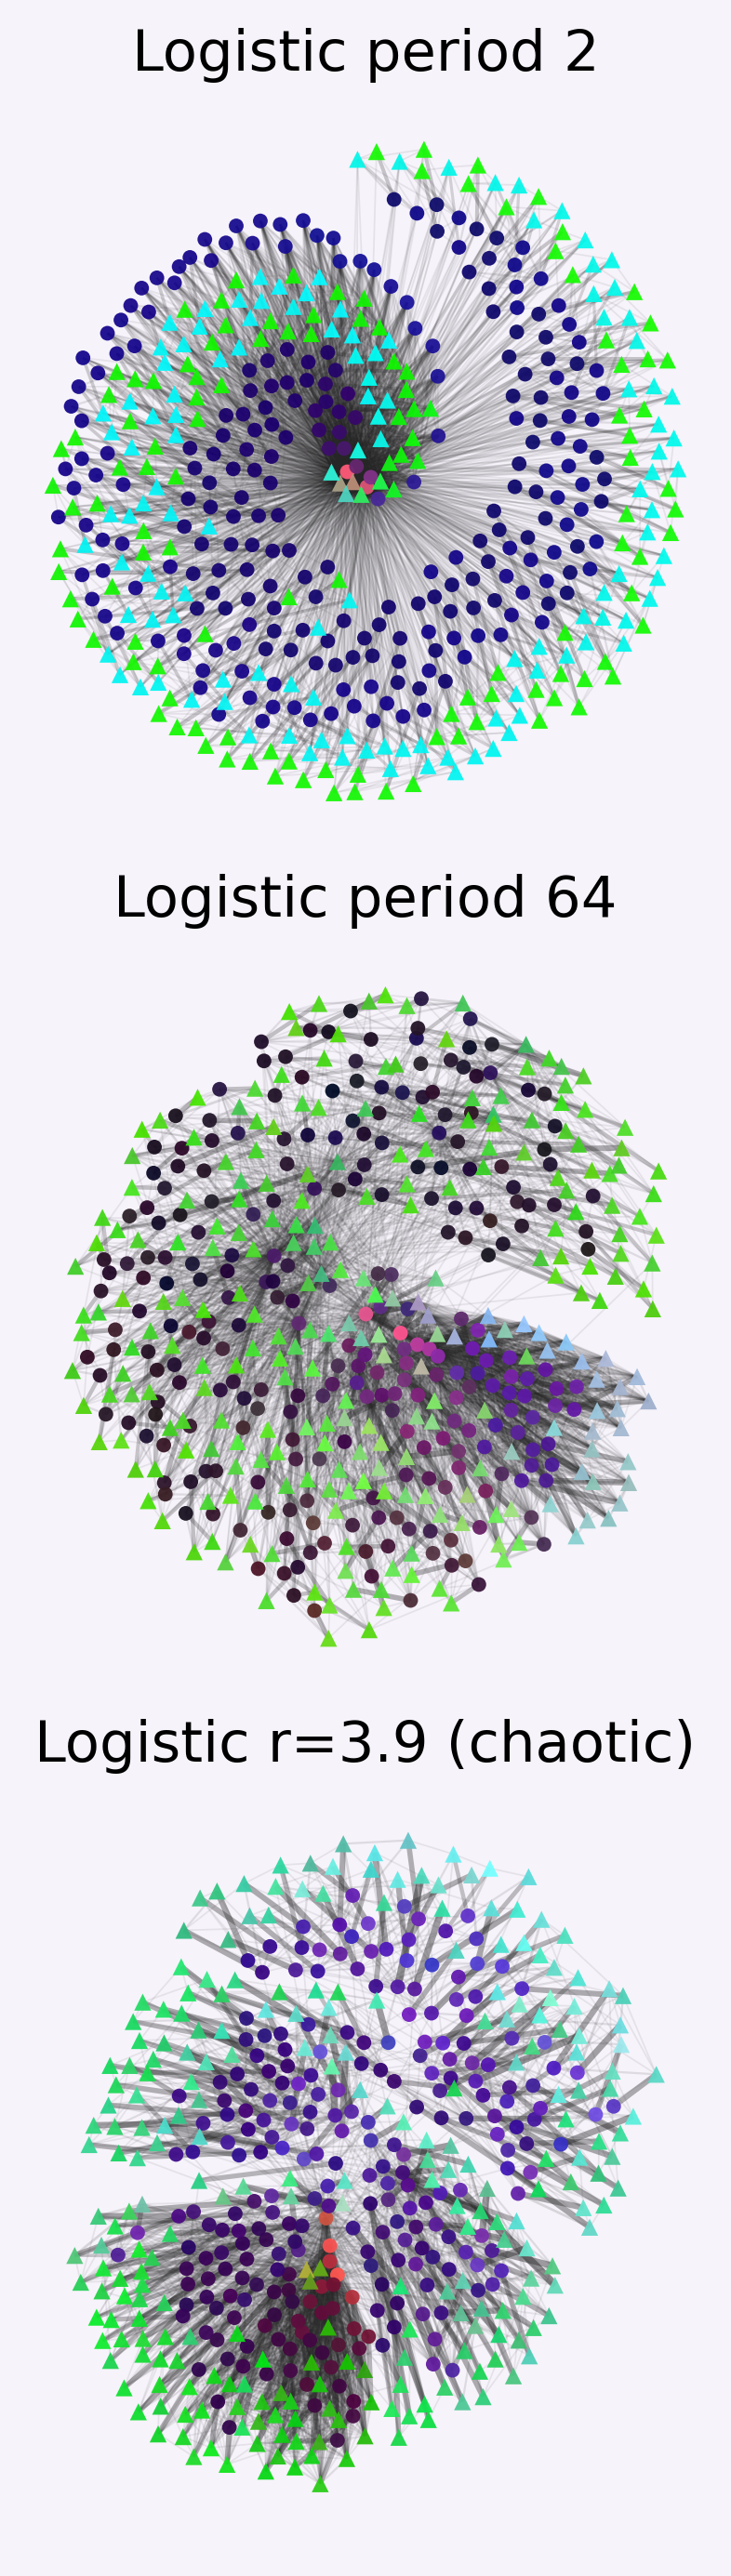

Saved: figure/overview-demo-token-graphs.pdf


In [9]:
LAYER_INDEX = int(available_layer_indices(DATA_ORDER[0])[-1])
graph_figure = plot_layer_across_inputs_global_edge_norm(
    layer_index=LAYER_INDEX,
    frac=CONTEXT_FRAC,
    data_names=DATA_ORDER,
    label_token_markers=False,
    save=True,
    save_filename=GRAPH_SAVE_FILENAME,
    show=True,
);
print(f'Saved: {FIGURE_OUTPUT_DIR / GRAPH_SAVE_FILENAME}')
